# 03 · Attribution: transport, window and information

**RQ2:** Which mechanism changes forecast quality? The original practical rules
selected windows independently. This study fixes windows for mechanism comparisons,
keeps dimension and smoothing fixed, and changes transport or retained nodes.
No setting is selected using these exploratory evaluation scores.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt

from spde_covariance.empirical_research import load_research_evidence

evidence = load_research_evidence(Path("../experiments/results/shfe-research"))
print(evidence["protocol"]["status"])
print("Numerical source:", evidence["manifest"]["git_revision"])
print("Original baseline source:", evidence["protocol"]["baseline_source_revision"])
assert evidence["protocol"]["baseline_summary_sha256"]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})


def table(rows, columns):
    print(" | ".join(columns))
    for row in rows:
        print(
            " | ".join(
                (
                    f"{row.get(c):.6g}" if isinstance(row.get(c), float) else str(row.get(c))
                    for c in columns
                )
            )
        )

exploratory development on inspected 2024–2025 data
Numerical source: a2f99054886b3154a311665cee7cacd8e6af483c
Original baseline source: d284718c0e465d39886500ab2d85904183266747


## Protocol and fair comparisons

The adjusted factor model fits $C$ through $V_\Delta(C)$; its A=0 counterpart
uses ordinary coefficient increments. Both use identical reconstructed states,
window and future actual-contract outcomes. Compare raw direct covariance and
10% diagonal shrinkage at the same nominal windows. Actual historical support
can differ because raw current contracts have finite history.

Nested masks retain all nodes, alternating nodes, then four nodes from the
alternating set. They affect factor reconstruction only. Raw direct baselines
retain full contract history, so masked-factor versus direct comparisons are
information stress tests. Within-mask adjusted/A=0 comparisons isolate transport
more closely. A 16-interval history cannot meet the original 20-pair baseline
minimum; do not relax that minimum to manufacture a comparison.

In [2]:
study = evidence["attribution"]
print(json.dumps(study["scope"], indent=2))
rows = [r for r in study["scores"] if r["mask"] == "all" and r["year"] == "all"]
table(rows, ["window", "exposure", "method", "count", "qlike", "risk_ratio"])

{
  "research_status": "exploratory_development_on_previously_inspected_period",
  "evaluation_start_after": "2023-12-31",
  "evaluation_end": "2025-12-31",
  "no_test_selection": true,
  "unchanged_original_benchmark": true,
  "target": "next_session_same_contract_cash_second_moment",
  "primary_score": "qlike",
  "secondary_score": "quadratic",
  "year_grouping": "outcome_session_calendar_year",
  "score_sample": "scores_common_all_four_methods_available_scores_method_specific",
  "paired_sample": "each_comparison_common_observations_by_exposure_mask_window_year",
  "short_history_baseline": "min_direct_count_unchanged_unavailable_if_window_too_short",
  "transport_ablation": "same_states_dimension_smoothing_window_and_raw_outcomes",
  "masking": "nested_price_independent_maturity_nodes_for_factor_reconstruction_only",
  "masked_baseline_information": "direct_baselines_retain_full_raw_contract_history",
  "matched_information_transport_claims": "use_within_mask_adjusted_vs_unadjusted

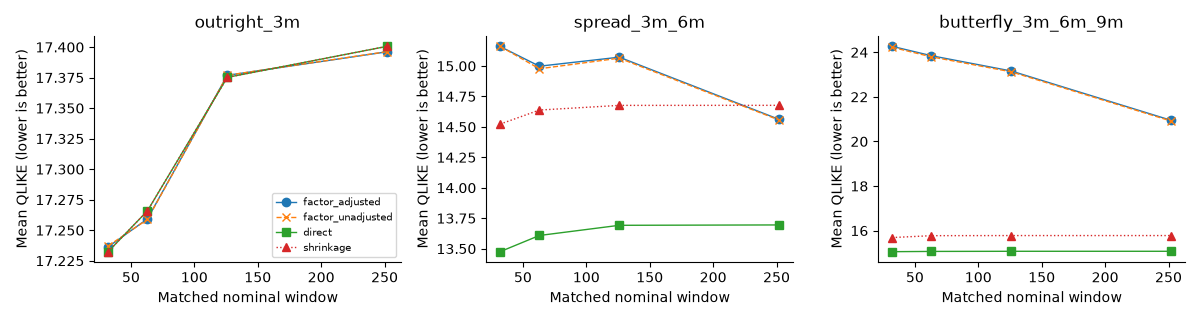

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, exposure in zip(axes, ["outright_3m", "spread_3m_6m", "butterfly_3m_6m_9m"], strict=True):
    for method, style in [
        ("factor_adjusted", "o-"),
        ("factor_unadjusted", "x--"),
        ("direct", "s-"),
        ("shrinkage", "^:"),
    ]:
        points = sorted(
            [r for r in rows if r["exposure"] == exposure and r["method"] == method],
            key=lambda r: r["window"],
        )
        ax.plot(
            [r["window"] for r in points],
            [r["qlike"] for r in points],
            style,
            label=method,
            linewidth=1,
        )
    ax.set(title=exposure, xlabel="Matched nominal window", ylabel="Mean QLIKE (lower is better)")
axes[0].legend(fontsize=7)
fig.tight_layout()
plt.show()

## Paired transport effect and masking stress

Differences are calculated on each method pair's identical scored observations.
Negative means favor the adjusted model. Report block uncertainty and availability
alongside the mean. A very small adjusted/A=0 effect is not evidence that transport
is mathematically unnecessary; it limits the measured forecasting claim here.

In [4]:
paired = [
    r
    for r in study["paired_comparisons"]
    if r["reference"] == "factor_unadjusted" and r["score"] == "qlike" and (r["year"] == "all")
]
table(
    paired,
    [
        "mask",
        "window",
        "exposure",
        "count",
        "mean",
        "bootstrap_standard_error",
        "bootstrap_percentile_95",
    ],
)
table(
    [r for r in study["availability"] if r["window"] == 16 and r["mask"] == "all"],
    ["window", "exposure", "method", "candidate_origins", "issued_count", "scored_count"],
)

mask | window | exposure | count | mean | bootstrap_standard_error | bootstrap_percentile_95
all | 16 | outright_3m | 484 | -0.00104938 | 0.000885503 | [-0.0029836866053074805, 0.0003766834094093128]
all | 16 | spread_3m_6m | 484 | -0.019554 | 0.0219372 | [-0.06475028931454324, 0.020923454933053046]
all | 16 | butterfly_3m_6m_9m | 484 | 0.0451675 | 0.013962 | [0.02147830222976421, 0.07369414680773471]
all | 32 | outright_3m | 484 | -0.000791151 | 0.000559594 | [-0.0019691422218801277, 0.000248209583105393]
all | 32 | spread_3m_6m | 484 | -0.00132208 | 0.0101301 | [-0.021132574644136683, 0.018583582886036242]
all | 32 | butterfly_3m_6m_9m | 484 | 0.0413657 | 0.00729364 | [0.028204405688102795, 0.05568670125465712]
all | 63 | outright_3m | 484 | 0.000405297 | 0.000467148 | [-0.000501732124109962, 0.0013042136912765141]
all | 63 | spread_3m_6m | 484 | 0.0209979 | 0.0153079 | [0.0002722891943210505, 0.056185653909442454]
all | 63 | butterfly_3m_6m_9m | 484 | 0.0500802 | 0.0156596 | [0.0249

In [5]:
for row in study["representation"]:
    print(row["mask"], json.dumps(row["reconstruction"], indent=2))
table(
    [
        r
        for r in study["available_scores"]
        if r["window"] == 126 and r["year"] == "all" and (r["method"] == "factor_adjusted")
    ],
    ["mask", "exposure", "count", "qlike", "risk_ratio"],
)
print("Numerical diagnostics:")
for row in study["numerical_diagnostics"]:
    print(
        row["mask"],
        row["window"],
        row["unavailable_reasons"],
        row["relative_covariance_error_bound_max"],
    )

all {
  "sessions": 969,
  "available_sessions": 969,
  "retained_nodes_min_median_p95_max": [
    9.0,
    11.0,
    11.0,
    12.0
  ],
  "design_condition_min_median_p95_max": [
    58.43154319219497,
    70.04439462151569,
    72.55115865057977,
    85.65768107841406
  ],
  "retained_node_rmse_min_median_p95_max": [
    9.68504838519093,
    48.577529217246976,
    144.04623917669127,
    968.4540482647277
  ]
}
alternate {
  "sessions": 969,
  "available_sessions": 969,
  "retained_nodes_min_median_p95_max": [
    5.0,
    6.0,
    6.0,
    6.0
  ],
  "design_condition_min_median_p95_max": [
    59.41480384032518,
    62.19571952469069,
    64.43792905730471,
    89.87259025189314
  ],
  "retained_node_rmse_min_median_p95_max": [
    5.043590016213716,
    40.71892315734609,
    128.05754971941192,
    1151.5206347052335
  ]
}
sparse4 {
  "sessions": 969,
  "available_sessions": 969,
  "retained_nodes_min_median_p95_max": [
    4.0,
    4.0,
    4.0,
    4.0
  ],
  "design_conditi

## Interpretation and next decision

At 252 intervals with all nodes, adjusted minus A=0 QLIKE is approximately
−0.000142 (outright), +0.00530 (spread) and +0.0323 (butterfly). The last difference
favors A=0; no favorable transport effect is established. Some masked estimates
improve under this fixed misspecified estimator, which does not make less
information intrinsically preferable.

Distinguish practical policy comparison from mechanism attribution. Neither a
masked curve model beating a baseline under one loss nor more coordinates alone
establishes an SPDE advantage. Use the joint-risk study to assess whether retained
residual information improves the economically relevant targets.

## Reproduction and research boundary

This notebook reads checksummed aggregate evidence, not raw exchange files.
The numerical algorithms are in `spde_covariance`; use the
[protocol](../docs/empirical-research-protocol.md) to rerun local calibration.
Execute this notebook with `uv run python scripts/check_notebook.py notebooks/03_performance_attribution.ipynb`.

The original historical benchmark remains fixed. New analyses on the inspected
2024–2025 period are exploratory, even though forecast issuance is past-only.
No final untouched confirmation period, executable trading backtest or physical
forcing identification is claimed. See the [roadmap](../README.md).